In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style('whitegrid')

In [53]:
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, label_binarize
import catboost
from sklearn.model_selection import train_test_split
from sklearn import model_selection, tree, preprocessing, metrics, linear_model
from sklearn.svm import LinearSVC
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LinearRegression, LogisticRegression, SGDClassifier
from sklearn.tree import DecisionTreeClassifier
from catboost import CatBoostClassifier, Pool, cv

In [54]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

In [55]:
train_data = pd.read_csv('train.csv')
test_data = pd.read_csv('test.csv')

**Visualização dados de treino**

In [56]:
train_data

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [57]:
train_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [58]:
train_data.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Visualização dados de teste**

In [59]:
test_data

,PassengerId,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...
413,1305,3,"Spector, Mr. Woolf",male,NaN,0,0,A.5. 3236,8.0500,NaN,S
414,1306,1,"Oliva y Ocana, Dona. Fermina",female,39.0,0,0,PC 17758,108.9000,C105,C
415,1307,3,"Saether, Mr. Simon Sivertsen",male,38.5,0,0,SOTON/O.Q. 3101262,7.2500,NaN,S
416,1308,3,"Ware, Mr. Frederick",male,NaN,0,0,359309,8.0500,NaN,S


In [60]:
test_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  418 non-null    int64  
 1   Pclass       418 non-null    int64  
 2   Name         418 non-null    str    
 3   Sex          418 non-null    str    
 4   Age          332 non-null    float64
 5   SibSp        418 non-null    int64  
 6   Parch        418 non-null    int64  
 7   Ticket       418 non-null    str    
 8   Fare         417 non-null    float64
 9   Cabin        91 non-null     str    
 10  Embarked     418 non-null    str    
dtypes: float64(2), int64(4), str(5)
memory usage: 36.1 KB


In [61]:
test_data.describe()

,PassengerId,Pclass,Age,SibSp,Parch,Fare
count,418.000000,418.000000,332.000000,418.000000,418.000000,417.000000
mean,1100.500000,2.265550,30.272590,0.447368,0.392344,35.627188
std,120.810458,0.841838,14.181209,0.896760,0.981429,55.907576
min,892.000000,1.000000,0.170000,0.000000,0.000000,0.000000
25%,996.250000,1.000000,21.000000,0.000000,0.000000,7.895800
50%,1100.500000,3.000000,27.000000,0.000000,0.000000,14.454200
75%,1204.750000,3.000000,39.000000,1.000000,0.000000,31.500000
max,1309.000000,3.000000,76.000000,8.000000,9.000000,512.329200


**Salvando ID para submissão final**

In [62]:
passengerID = test_data['PassengerId']
passengerID

0       892
1       893
2       894
3       895
4       896
       ... 
413    1305
414    1306
415    1307
416    1308
417    1309
Name: PassengerId, Length: 418, dtype: int64

**Unindo dados de treino e teste para tratamento de dados**

In [63]:
titanic_data = pd.concat([train_data, test_data], ignore_index = True)

**Visualização de colunas que precisam de tratamento para nulos**

In [64]:
 titanic_data.isnull().sum()

PassengerId       0
Survived        418
Pclass            0
Name              0
Sex               0
Age             263
SibSp             0
Parch             0
Ticket            0
Fare              1
Cabin          1014
Embarked          2
dtype: int64

**Guardando os id's para separação dos dados depois do tratamento**

In [65]:
train_idx = len(train_data)
test_idx = len(titanic_data) - len(test_data)

**Criação de novo DataFrame para tratamento de daods**

In [66]:
new_dataFrame = pd.DataFrame()

**Vizualização geral de sobreviventes**

<Axes: xlabel='Survived', ylabel='count'>

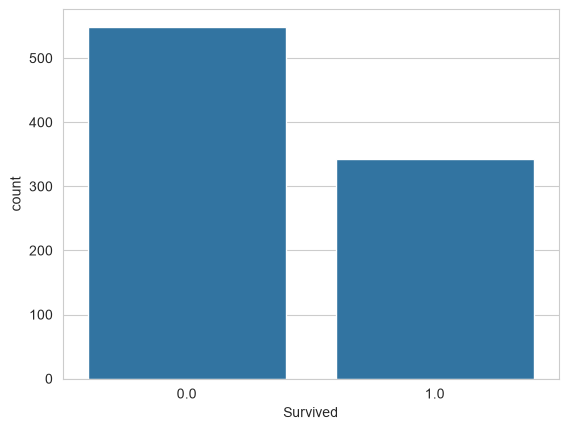

In [67]:
sns.countplot(data = titanic_data, x = 'Survived')

**Função que analisa uma coluna e gera um gráfico**

Quantidade valores únicos: 2

Valores únicos: [ 0.  1. nan]

Quantidade valores nulos: 418

Quantidade por opção: 
Survived
0.0    549
1.0    342
Name: count, dtype: int64


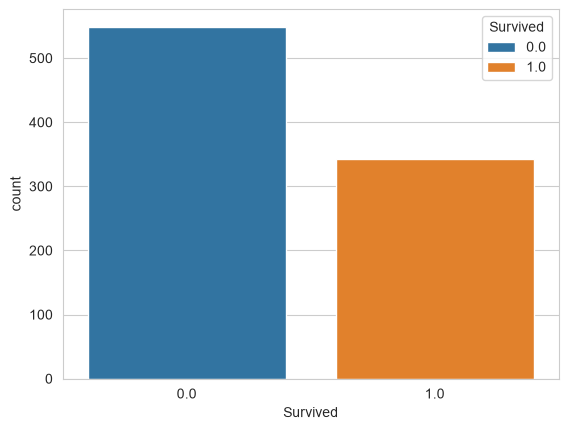

In [68]:
def titanic_analyzing (data, column, count = True):
    print(f'Quantidade valores únicos: {data[column].nunique()}')
    print(f'\nValores únicos: {data[column].unique()}')
    print(f'\nQuantidade valores nulos: {data[column].isnull().sum()}')
    print(f'\nQuantidade por opção: \n{data[column].value_counts()}')

    if count:
        sns.countplot(data = data, x = column, hue = 'Survived')
    else:
        sns.displot(data[column], kde = True)

titanic_analyzing(titanic_data, 'Survived')


**Tratamento de dados usando o novo DataFrame**

In [69]:
new_dataFrame['Survived'] = titanic_data['Survived']

Quantidade valores únicos: 3

Valores únicos: [3 1 2]

Quantidade valores nulos: 0

Quantidade por opção: 
Pclass
3    709
1    323
2    277
Name: count, dtype: int64


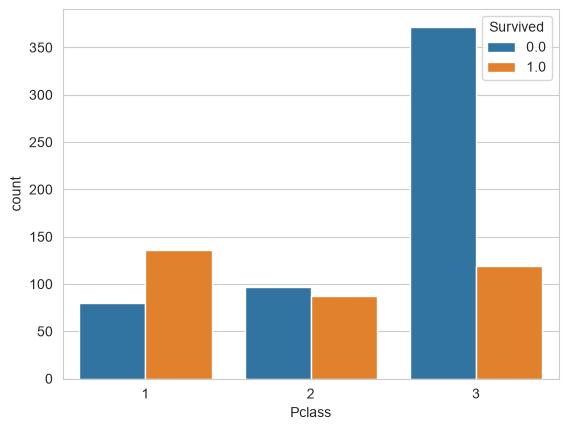

In [70]:
titanic_analyzing(titanic_data, 'Pclass')

In [71]:
new_dataFrame['Pclass'] = titanic_data['Pclass']

In [72]:
titanic_data['Sex'] = titanic_data['Sex'].map({'female': 1, 'male': 0})

Quantidade valores únicos: 2

Valores únicos: [0 1]

Quantidade valores nulos: 0

Quantidade por opção: 
Sex
0    843
1    466
Name: count, dtype: int64


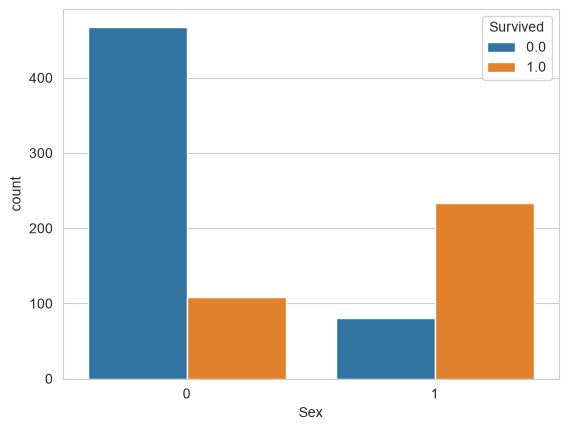

In [73]:
titanic_analyzing(titanic_data, 'Sex')

In [74]:
new_dataFrame['Sex'] = titanic_data['Sex']

Quantidade valores únicos: 98

Valores únicos: [22.   38.   26.   35.     nan 54.    2.   27.   14.    4.   58.   20.
 39.   55.   31.   34.   15.   28.    8.   19.   40.   66.   42.   21.
 18.    3.    7.   49.   29.   65.   28.5   5.   11.   45.   17.   32.
 16.   25.    0.83 30.   33.   23.   24.   46.   59.   71.   37.   47.
 14.5  70.5  32.5  12.    9.   36.5  51.   55.5  40.5  44.    1.   61.
 56.   50.   36.   45.5  20.5  62.   41.   52.   63.   23.5   0.92 43.
 60.   10.   64.   13.   48.    0.75 53.   57.   80.   70.   24.5   6.
  0.67 30.5   0.42 34.5  74.   22.5  18.5  67.   76.   26.5  60.5  11.5
  0.33  0.17 38.5 ]

Quantidade valores nulos: 263

Quantidade por opção: 
Age
24.00    47
22.00    43
21.00    41
30.00    40
18.00    39
         ..
60.50     1
11.50     1
0.33      1
0.17      1
38.50     1
Name: count, Length: 98, dtype: int64


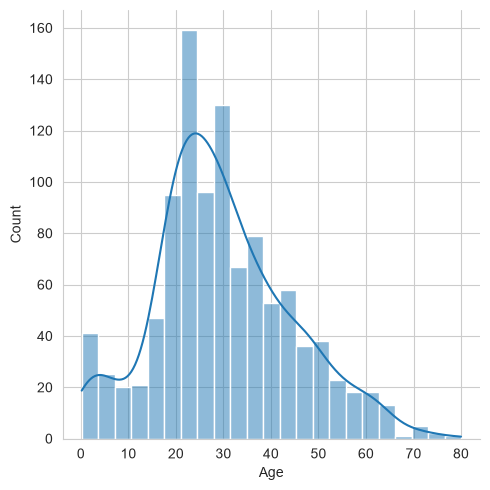

In [75]:
titanic_analyzing(titanic_data, 'Age', False)

In [76]:
titanic_data.corr(numeric_only=True)

,PassengerId,Survived,Pclass,Sex,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.038354,-0.013406,0.028814,-0.055224,0.008942,0.031428
Survived,-0.005007,1.000000,-0.338481,0.543351,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.038354,-0.338481,1.000000,-0.124617,-0.408106,0.060832,0.018322,-0.558629
Sex,-0.013406,0.543351,-0.124617,1.000000,-0.063645,0.109609,0.213125,0.185523
Age,0.028814,-0.077221,-0.408106,-0.063645,1.000000,-0.243699,-0.150917,0.178740
SibSp,-0.055224,-0.035322,0.060832,0.109609,-0.243699,1.000000,0.373587,0.160238
Parch,0.008942,0.081629,0.018322,0.213125,-0.150917,0.373587,1.000000,0.221539
Fare,0.031428,0.257307,-0.558629,0.185523,0.178740,0.160238,0.221539,1.000000


In [77]:
titanic_data['Age'] = titanic_data['Age'].fillna(
    titanic_data.groupby('Pclass')['Age'].transform('mean').round()
)

In [78]:
new_dataFrame['Age'] = titanic_data['Age']

Quantidade valores únicos: 7

Valores únicos: [1 0 3 4 2 5 8]

Quantidade valores nulos: 0

Quantidade por opção: 
SibSp
0    891
1    319
2     42
4     22
3     20
8      9
5      6
Name: count, dtype: int64


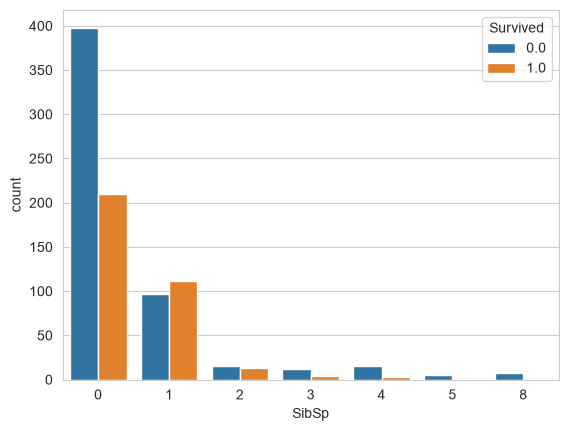

In [79]:
titanic_analyzing(titanic_data, 'SibSp')

In [80]:
new_dataFrame['SibSp'] = titanic_data['SibSp']

Quantidade valores únicos: 8

Valores únicos: [0 1 2 5 3 4 6 9]

Quantidade valores nulos: 0

Quantidade por opção: 
Parch
0    1002
1     170
2     113
3       8
5       6
4       6
6       2
9       2
Name: count, dtype: int64


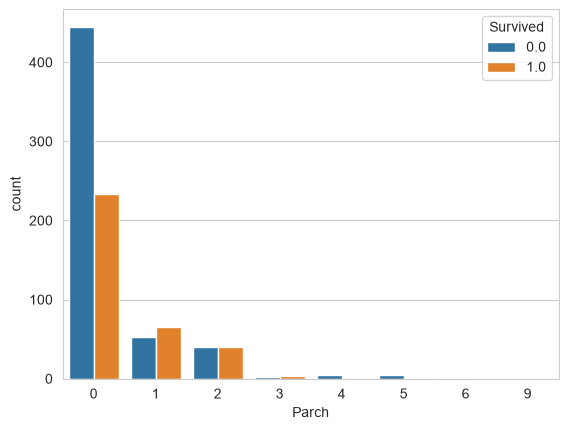

In [81]:
titanic_analyzing(titanic_data, 'Parch')

In [82]:
new_dataFrame['Parch'] = titanic_data['Parch']

In [83]:
titanic_data['FamilySize'] = titanic_data['SibSp'] + titanic_data['Parch'] + 1

Quantidade valores únicos: 9

Valores únicos: [ 2  1  5  3  7  6  4  8 11]

Quantidade valores nulos: 0

Quantidade por opção: 
FamilySize
1     790
2     235
3     159
4      43
6      25
5      22
7      16
11     11
8       8
Name: count, dtype: int64


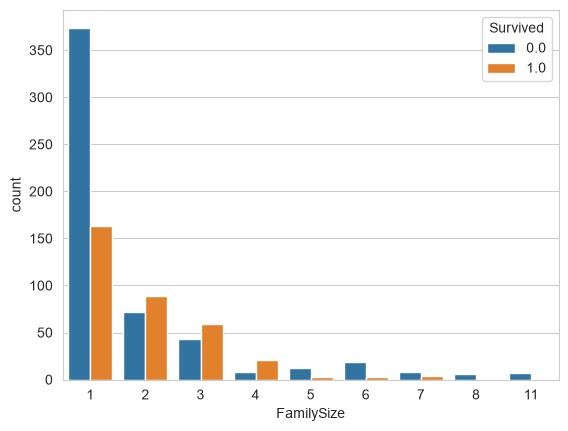

In [84]:
titanic_analyzing(titanic_data, 'FamilySize')

In [85]:
new_dataFrame['FamilySize'] = titanic_data['FamilySize']

Quantidade valores únicos: 281

Valores únicos: [  7.25    71.2833   7.925   53.1      8.05     8.4583  51.8625  21.075
  11.1333  30.0708  16.7     26.55    31.275    7.8542  16.      29.125
  13.      18.       7.225   26.       8.0292  35.5     31.3875 263.
   7.8792   7.8958  27.7208 146.5208   7.75    10.5     82.1708  52.
   7.2292  11.2417   9.475   21.      41.5792  15.5     21.6792  17.8
  39.6875   7.8     76.7292  61.9792  27.75    46.9     80.      83.475
  27.9     15.2458   8.1583   8.6625  73.5     14.4542  56.4958   7.65
  29.      12.475    9.       9.5      7.7875  47.1     15.85    34.375
  61.175   20.575   34.6542  63.3583  23.      77.2875   8.6542   7.775
  24.15     9.825   14.4583 247.5208   7.1417  22.3583   6.975    7.05
  14.5     15.0458  26.2833   9.2167  79.2      6.75    11.5     36.75
   7.7958  12.525   66.6      7.3125  61.3792   7.7333  69.55    16.1
  15.75    20.525   55.      25.925   33.5     30.6958  25.4667  28.7125
   0.      15.05    39.     

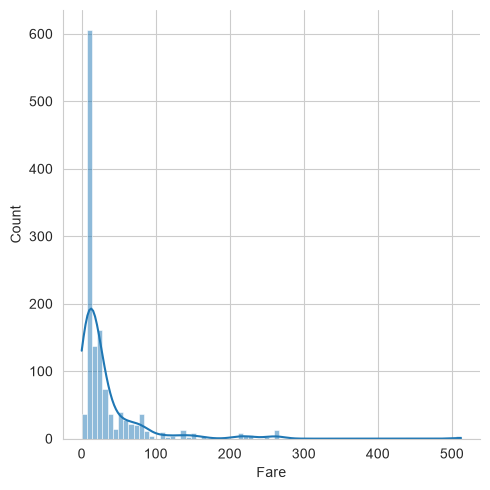

In [86]:
titanic_analyzing(titanic_data, 'Fare', False)

In [87]:
titanic_data[titanic_data['Fare'].isnull()]

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked,FamilySize
1043,1044,NaN,3,"Storey, Mr. Thomas",0,60.5,0,0,3701,NaN,NaN,S,1


In [88]:
titanic_data['Fare'] = titanic_data['Fare'].fillna(
    titanic_data.groupby('Pclass')['Fare'].transform('mean').round()
)

In [89]:
new_dataFrame['Fare'] = titanic_data['Fare']

In [90]:
titanic_data['HasCabin'] = titanic_data['Cabin'].notnull().astype(int)

In [91]:
new_dataFrame['HasCabin'] = titanic_data['HasCabin']

In [92]:
titanic_data['Embarked'] = titanic_data['Embarked'].fillna(titanic_data['Embarked'].mode()[0])

In [93]:
new_dataFrame['Embarked'] = titanic_data['Embarked']

In [94]:
titanic_data['Title'] = titanic_data['Name'].apply(lambda name: name.split(',')[1].split('.')[0].strip())

In [95]:
titanic_data['Title'] = [n if n in ['Mr', 'Miss', 'Mrs', 'Master'] else 'Person' for n in titanic_data['Title']]

In [96]:
new_dataFrame['Title'] = titanic_data['Title']

In [97]:
pclass = pd.get_dummies(new_dataFrame['Pclass'], prefix = 'Pclass', drop_first = True)
title = pd.get_dummies(new_dataFrame['Title'], prefix = 'Title', drop_first = True)
embarked = pd.get_dummies(new_dataFrame['Embarked'], prefix = 'Embarked', drop_first = True)

In [98]:
final_titanic_data = pd.concat([new_dataFrame, pclass, title, embarked], axis = 1)

In [99]:
final_titanic_data = final_titanic_data.drop(columns=['Pclass', 'Title', 'Embarked'])

In [100]:
final_titanic_data

,Survived,Sex,Age,SibSp,Parch,FamilySize,Fare,HasCabin,Pclass_2,Pclass_3,Title_Miss,Title_Mr,Title_Mrs,Title_Person,Embarked_Q,Embarked_S
0,0.0,0,22.0,1,0,2,7.2500,0,False,True,False,True,False,False,False,True
1,1.0,1,38.0,1,0,2,71.2833,1,False,False,False,False,True,False,False,False
2,1.0,1,26.0,0,0,1,7.9250,0,False,True,True,False,False,False,False,True
3,1.0,1,35.0,1,0,2,53.1000,1,False,False,False,False,True,False,False,True
4,0.0,0,35.0,0,0,1,8.0500,0,False,True,False,True,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1304,NaN,0,25.0,0,0,1,8.0500,0,False,True,False,True,False,False,False,True
1305,NaN,1,39.0,0,0,1,108.9000,1,False,False,False,False,False,True,False,False
1306,NaN,0,38.5,0,0,1,7.2500,0,False,True,False,True,False,False,False,True
1307,NaN,0,25.0,0,0,1,8.0500,0,False,True,False,True,False,False,False,True


**Separar dados de Treino dos dados de Teste e tratamentos finais**

In [101]:
train_data = final_titanic_data[:train_idx].copy()
test_data = final_titanic_data[train_idx:].copy()

In [102]:
train_data['Survived'] = train_data['Survived'].astype(int)

In [103]:
X = train_data.drop('Survived', axis = 1)
Y = train_data['Survived']

In [104]:
X_test = test_data.drop('Survived', axis = 1)

**Função para detecção de acurácia**

In [105]:
def analise_acuracia(algoritmo, X_train, Y_train, validacao_cruzada):
    modelo = algoritmo.fit(X_train, Y_train)
    acuracia = round(modelo.score(X_train, Y_train) * 100, 2)

    train_pred = model_selection.cross_val_predict(algoritmo, X_train, Y_train, cv = validacao_cruzada, n_jobs = -1)
    acuracia_vc = round(metrics.accuracy_score(Y_train, train_pred) * 100, 2)

    return acuracia, acuracia_vc

**Testes de modelos**

In [106]:
#Randon Forest

acc_rf, acc_vc_rf = analise_acuracia(RandomForestClassifier(), X, Y, 10)
print(f'Acuracia: {acc_rf}')
print(f'Acuracia Validação Cruzada: {acc_vc_rf}')

Acuracia: 98.65
Acuracia Validação Cruzada: 81.26


In [107]:
#Logistic Regression
acc_log, acc_vc_log = analise_acuracia(LogisticRegression(max_iter = 1000), X, Y, 10)
print(f'Acuracia: {acc_log}')
print(f'Acuracia Validação Cruzada: {acc_vc_log}')

Acuracia: 83.05
Acuracia Validação Cruzada: 82.94


In [108]:
#K-Nearest Neighbours

acc_knn, acc_vc_knn = analise_acuracia(KNeighborsClassifier(), X, Y, 10)
print(f"Acurácia: {acc_knn}")
print(f"Acurácia Validação Cruzada: {acc_vc_knn}")

Acurácia: 80.25
Acurácia Validação Cruzada: 72.84


In [109]:
#Gaussian Naive Bayes

acc_gaussian, acc_vc_gaussian = analise_acuracia(GaussianNB(), X, Y, 10)
print(f"Acurácia: {acc_gaussian}")
print(f"Acurácia Validação Cruzada: {acc_vc_gaussian}")

Acurácia: 79.12
Acurácia Validação Cruzada: 78.9


In [110]:
#Linear Support Vector Machines

acc_linear_svc, acc_vc_linear_svc = analise_acuracia(LinearSVC(dual=False), X, Y, 10)
print(f"Acurácia: {acc_linear_svc}")
print(f"Acurácia Validação Cruzada: {acc_vc_linear_svc}")

Acurácia: 83.28
Acurácia Validação Cruzada: 83.16


In [111]:
#Stochastic Gradient Descent

acc_sgd, acc_vc_sgd = analise_acuracia(SGDClassifier(), X, Y, 10)
print(f"Acurácia: {acc_sgd}")
print(f"Acurácia Validação Cruzada: {acc_vc_sgd}")

Acurácia: 71.6
Acurácia Validação Cruzada: 73.18


In [112]:
#Decision Tree Classifier

acc_dt, acc_vc_dt = analise_acuracia(DecisionTreeClassifier(), X, Y, 10)
print(f"Acurácia: {acc_dt}")
print(f"Acurácia Validação Cruzada: {acc_vc_dt}")

Acurácia: 98.65
Acurácia Validação Cruzada: 78.56


In [113]:
#Gradient Boost Trees

acc_gbt, acc_vc_gbt = analise_acuracia(GradientBoostingClassifier(), X, Y, 10)
print(f"Acurácia: {acc_gbt}")
print(f"Acurácia Validação Cruzada: {acc_vc_gbt}")

Acurácia: 89.79
Acurácia Validação Cruzada: 83.16


In [114]:
params = dict(     
    max_depth = [n for n in range(1, 5)],     
    min_samples_split = [n for n in range(2, 6)], 
    min_samples_leaf = [n for n in range(2, 6)],     
    n_estimators = [n for n in range(10, 50, 10)],
)

In [115]:
gbc = GradientBoostingClassifier()

In [116]:
gbc_cv = GridSearchCV(estimator = gbc, param_grid = params, cv = 10) 
gbc_cv.fit(X, Y)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",GradientBoostingClassifier()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [1, 2, ...], 'min_samples_leaf': [2, 3, ...], 'min_samples_split': [2, 3, ...], 'n_estimators': [10, 20, ...]}"
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verb

In [117]:
print(f"Melhor pontuação: {gbc_cv.best_score_}")

Melhor pontuação: 0.837278401997503


In [118]:
gradientBoostingClassifier_pred = gbc_cv.predict(X_test)

In [119]:
kaggle_submit = pd.DataFrame({'PassengerId': passengerID, 'Survived': gradientBoostingClassifier_pred})
kaggle_submit.to_csv('./titanic_gradient_boosting_pred.csv', index=False)